# Handwritten Digit Recognition with Convolutional Neural Networks

## Project Overview

This project explores handwritten digit classification using a Convolutional Neural Network (CNN) built with PyTorch.

The objective is to classify grayscale images of handwritten digits into one of ten classes (0–9). The project uses the Digit Recognizer dataset from Kaggle, which contains 28 × 28 pixel images of handwritten digits.

The workflow covers:

- Exploratory data analysis and image visualization

- Data preparation and preprocessing

- Custom data augmentation techniques

- CNN architecture design and training

- Model evaluation and error analysis

- Prediction generation for the Kaggle test set

A particular focus is placed on investigating how different data augmentation strategies affect model performance, including geometric transformations, random erasing, and morphological operations.

## Objective

The goal is not only to achieve high classification accuracy, but also to understand how preprocessing, augmentation, and model design influence the model's ability to recognize variations in handwritten digits.

## 1. Dataset Exploration

Before building the model, we first inspect the dataset structure and visualize a few samples to understand how the handwritten digits are represented.

### Dataset Structure

The dataset consists of two CSV files:

- **Training set:** 42,000 labeled images.
- **Test set:** 28,000 unlabeled images.

Each image is represented by 784 pixel values, corresponding to a flattened 28 × 28 grayscale image.

The training set contains an additional `label` column, representing the digit (0–9) associated with each image. The test set contains only pixel values, as its labels are not provided.

Pixel intensities range from 0 (black) to 255 (white).

In [ ]:
import numpy as np
import pandas as pd


df_train = pd.read_csv("/kaggle/input/digit-recognizer/train.csv")
df_test = pd.read_csv("/kaggle/input/digit-recognizer/test.csv")

print(df_test.shape)
print(df_train.shape)
df_train.head()

(28000, 784)
(42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [81]:
df_test.head()

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Image Representation

Each row of pixel data is reshaped into a 28 × 28 grayscale image for visualization and model input.

Although all images share the same dimensions, handwriting varies in stroke thickness, shape, orientation, and positioning. These variations make the classification task more challenging and motivate the use of data augmentation during training.

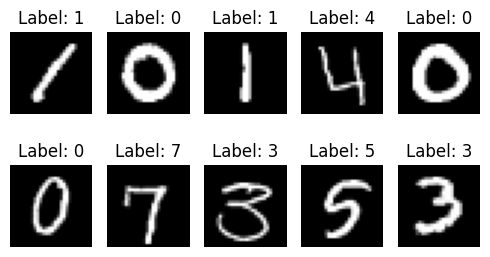

In [ ]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(2, 5, figsize=(5, 3))

for i, ax in enumerate(axes.flat):
    image = df_train.iloc[i, 1:].values.reshape(28, 28)
    label = df_train.iloc[i, 0]

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Data Preparation

Before training the CNN, the data needs to be prepared for use with PyTorch.

This involves splitting the labeled data into training and validation sets, converting the tabular pixel data into image tensors, and creating data loaders for efficient batch processing.

### Train-Validation Split

The labeled dataset is divided into two subsets:

- **Training set (90%):** Used to train the model and update its parameters.
- **Validation set (10%):** Used to monitor model performance on unseen data and guide model selection.

The split uses stratification based on the target label. This preserves approximately the same distribution of digit classes in both subsets, reducing the risk of an unrepresentative validation set.

A fixed `random_state` ensures that the same split is reproduced each time the notebook is executed.

The validation set is kept separate from the training process: it is not used to calculate gradients or update model parameters.

In [56]:
from sklearn.model_selection import train_test_split


data_train, data_val = train_test_split(df_train, test_size=0.10, random_state=42, stratify=df_train["label"])

data_train.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
27053,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
33380,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20034,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
20793,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3214,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Custom PyTorch Dataset

The original data is stored in tabular format, with each image represented by a row of 784 pixel values. PyTorch models, however, work with tensors rather than raw DataFrame rows.

To bridge this gap, a custom `Dataset` class is implemented.

Its responsibilities are to:

- Retrieve an image and its corresponding label using an index.
- Reshape the flattened pixel values into a 28 × 28 grayscale image.
- Convert pixel values to `uint8` before applying image transformations.
- Apply the transformations specified for the corresponding dataset.
- Return the processed image and its label.

The same class also handles the unlabeled test dataset, where only image data is available.

In [57]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
import cv2


class CustomDataset(Dataset):
    def __init__(self, dataset, transform=None, is_test=False):
        
        self.data = dataset
        self.transform = transform
        self.is_test = is_test
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        if self.is_test == False:
            label = self.data.iloc[idx, 0]
            image = self.data.iloc[idx, 1:].values.reshape(28, 28).astype('uint8')
        else:
            label = 'None'
            image = self.data.iloc[idx, :].values.reshape(28, 28).astype('uint8')     
        
        if self.transform != None:
            image = self.transform(image)
            
        return image, label
         

## 3. Data Augmentation

Data augmentation is used to increase the diversity of training samples by applying transformations to existing images.

For handwritten digit recognition, this is particularly useful because the same digit can be written in many different ways, varying in position, orientation, size, and stroke thickness.

In this project, several augmentation techniques are investigated to evaluate their effect on model generalization:

- **Random affine transformations:** Introduce geometric variations in digit position, orientation, and scale.
- **Random erasing:** Simulates partially occluded or missing portions of a digit.
- **Morphological operations:** Modify stroke thickness through dilation or erosion.

Each transformation is applied probabilistically, allowing the model to encounter both original and augmented images during training.

### 3.1 Random Erasing

Random erasing simulates situations where a portion of a handwritten digit is missing or obscured.

The implementation selects a random non-background pixel and places a square patch around it. The pixels inside this patch are set to zero, effectively removing a small part of the digit.

The transformation is controlled by two parameters:

- `erase_size`: Approximate size of the erased square region.
- `p`: Probability of applying the transformation.

By exposing the model to partially erased digits, this technique encourages it to recognize digits even when some local visual information is missing.

In [ ]:
import random
from PIL import Image


class RandomEraseDigitPart:
    def __init__(self, erase_size=5, p=0.5):
        """
        erase_size: number of pixels to erase (approximate size of the patch)
        p: probability of applying the transform
        """
        self.erase_size = erase_size
        self.p = p

    def __call__(self, img):
        if random.random() > self.p:
            return img
    
        img_np = np.array(img)
    
        # Get coordinates of non-zero pixels
        coords = np.argwhere(img_np > 0)
    
        if len(coords) == 0:
            return img
    
        # Pick a random pixel belonging to the digit
        y, x = coords[random.randint(0, len(coords) - 1)]
    
        # Calculate patch boundaries
        half = self.erase_size // 2
    
        y_min = max(0, y - half)
        y_max = min(img_np.shape[0], y + half)
    
        x_min = max(0, x - half)
        x_max = min(img_np.shape[1], x + half)
    
        # Erase the patch
        img_np[y_min:y_max, x_min:x_max] = 0
    
        return Image.fromarray(img_np.astype(np.uint8))


### 3.2 Morphological Operations

Morphological operations modify the shape of foreground regions in an image. In handwritten digit recognition, they can be used to simulate variations in stroke thickness.

This project implements two operations:

- **Dilation:** Expands foreground regions, making digit strokes thicker.
- **Erosion:** Shrinks foreground regions, making digit strokes thinner.

The operations use a cross-shaped structuring element. Its size determines the neighborhood considered when modifying each pixel.

The custom `RandomMorphology` transformation supports the following parameters:

- `mode`: Selects either dilation or erosion.
- `kernel_size`: Defines the dimensions of the structuring element.
- `p`: Probability of applying the operation.

Only one morphological operation is applied per invocation of the transformation.

In [ ]:
import cv2


class RandomMorphology:
    def __init__(self, mode="erosion", kernel_size=3, p=0.5):
        self.mode = mode
        self.se = cv2.MORPH_CROSS
        self.kernel = cv2.getStructuringElement(self.se, (kernel_size, kernel_size))
        self.p = p

    def __call__(self, img):
        if np.random.rand() > self.p:
            return img

        img = np.array(img)

        if self.mode == "erosion":
            img = cv2.erode(img, self.kernel)
        elif self.mode == "dilation":
            img = cv2.dilate(img, self.kernel)

        return Image.fromarray(img.astype(np.uint8))

### 3.3 Random Affine Transformations

Affine transformations introduce geometric variations while preserving the overall structure of handwritten digits.

The training pipeline uses `RandomAffine` to apply three types of transformations:

- **Rotation:** Randomly rotates an image within a specified angular range.
- **Translation:** Randomly shifts the digit horizontally and vertically.
- **Scaling:** Randomly increases or decreases the digit size.

These variations help the model become less sensitive to small differences in how digits are positioned and written.

### Image Preprocessing

All images undergo the same basic preprocessing steps:

1. **Conversion to PIL Image:** Allows the image to be processed by the torchvision transformations.
2. **Conversion to Tensor:** Converts the image into a PyTorch tensor and scales pixel intensities from the range [0, 255] to [0, 1].
3. **Normalization:** Applies a transformation using a mean and standard deviation of 0.5.

Normalization transforms pixel values to approximately the range [-1, 1]:

$$x_{\text{norm}} = \frac{x - 0.5}{0.5}$$

Two separate transformation pipelines are used. The training pipeline additionally includes data augmentation, while validation and test images receive only the basic preprocessing steps.

This ensures that validation and test data retain their original characteristics rather than being artificially modified.

**Active Configuration**

The augmentation techniques are implemented as separate transformations so that their effects can be investigated independently and in combination.

The current configuration uses random affine transformations, applied with a probability of 0.6. Random erasing and morphological operations are disabled in this experiment.

This separation allows controlled comparisons between different augmentation strategies.

In [ ]:
# define transformations and create datasets

transform_train = transforms.Compose([
                          transforms.ToPILImage(),
                          # RandomEraseDigitPart(erase_size=4, p=0.4),
                          # RandomMorphology(mode='dilation', kernel_size=3, p=0.1),
                          transforms.RandomApply([transforms.RandomAffine(degrees=(-10, 10), translate=(0.04, 0.04), scale=(0.9, 1.1))], p=0.6),
                          transforms.ToTensor(),
                          transforms.Normalize((0.5,), (0.5,))
            ])

transform = transforms.Compose([
                          transforms.ToPILImage(),
                          transforms.ToTensor(),
                          transforms.Normalize((0.5,), (0.5,))
            ])

train_set = CustomDataset(data_train, transform_train)
val_set = CustomDataset(data_val, transform)
test_set = CustomDataset(df_test, transform, is_test=True)


### DataLoaders

PyTorch `DataLoader` objects are used to load the datasets in batches rather than processing all images simultaneously.

A batch size of 64 is used for all three datasets.

- **Training loader:** Shuffles the training samples at the beginning of each epoch to reduce dependence on sample ordering.
- **Validation loader:** Preserves sample order, since shuffling is unnecessary during evaluation.
- **Test loader:** Also preserves sample order so that predictions remain aligned with the original test dataset.

Batch processing makes training more memory-efficient and allows the model to update its parameters using mini-batches of samples.

In [ ]:
# create dataloaders

batch = 64

train_loader = DataLoader(train_set, batch_size=batch, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch, shuffle=False)

### Visualizing Augmented Samples

To inspect the effect of the training transformations, an individual sample is retrieved from the training dataset and the resulting image is visualized.

Since the transformations are applied probabilistically, the displayed image may be unchanged or may contain one or more augmentations.

This provides a visual sanity check that the transformations are being applied as intended.

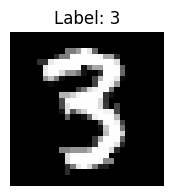

In [84]:
# show transformed image

im, lab = train_set[0]

plt.figure(figsize=(2, 2))
plt.imshow(im.squeeze(), cmap="gray")
plt.title(f"Label: {lab}")
plt.axis("off")
plt.show()

### Visualizing a Training Batch

The following visualization displays a batch of images retrieved from the training DataLoader.

Unlike the previous example, which shows a single transformed sample, this grid provides a broader view of the images presented to the model during training.

Because augmentation is stochastic, different iterations may produce different versions of the same underlying images.

tensor([8, 6, 1, 6, 5, 8, 6, 3, 2, 3, 8, 1, 8, 9, 0, 8, 4, 3, 8, 4, 5, 9, 8, 4,
        5, 8, 9, 7, 8, 3, 9, 3, 9, 0, 8, 4, 9, 5, 5, 4, 5, 6, 0, 5, 2, 6, 9, 7,
        8, 3, 4, 0, 5, 1, 6, 8, 9, 7, 1, 8, 1, 9, 4, 0])


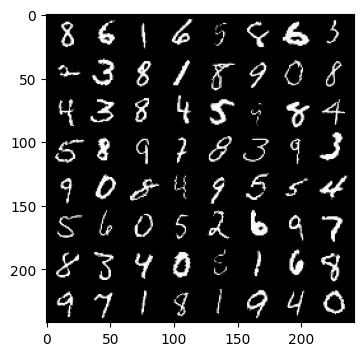

In [62]:
# show one train batch

import torchvision


def imshow(img):
    npimg = img.numpy()
    plt.figure(figsize=(4, 4))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(train_loader)

images, labels = next(dataiter)

print(labels)
imshow(torchvision.utils.make_grid(images))

### Visualizing a Test Batch

A batch from the test DataLoader is displayed to verify that test images are loaded and preprocessed correctly.

Unlike training images, test images undergo only tensor conversion and normalization. No data augmentation is applied.

This ensures that predictions are generated from the original test images rather than artificially modified versions.

('None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None', 'None')


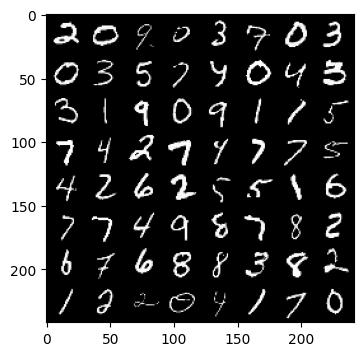

In [63]:
# show one test batch

dataiter = iter(test_loader)

images, labels = next(dataiter)

print(labels)
imshow(torchvision.utils.make_grid(images))

## 4. Model Architecture and Training

With the data prepared and the input pipeline verified, we can now define the convolutional neural network and configure the training process.

In [64]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


### 4.1 Convolutional Neural Network Architecture

A Convolutional Neural Network (CNN) is used to classify the handwritten digit images.

CNNs are particularly suitable for image classification because convolutional layers learn local visual patterns, such as edges, curves, and combinations of strokes. These features are progressively combined into more complex representations that help distinguish between digit classes.

In [65]:
import torch.nn as nn


class Network(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3) # 28-3+1=26
        self.bn1 = nn.BatchNorm2d(16)
        self.act1 = nn.ReLU()
        #self.pool1 = nn.MaxPool2d(2) # (28-2)/2+1=14
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(32)
        self.act2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2) # 7
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3)
        self.bn3 = nn.BatchNorm2d(64)
        self.act3 = nn.ReLU()
        #self.pool3 = nn.MaxPool2d(2) # 3
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3)
        self.bn4 = nn.BatchNorm2d(128)
        self.act4 = nn.ReLU()
        #self.pool4 = nn.MaxPool2d(2) # 1
        self.conv5 = nn.Conv2d(128, 128, kernel_size=3)
        self.bn5 = nn.BatchNorm2d(128)
        self.act5 = nn.ReLU()
        self.fc1 = nn.Linear(128 * 6 * 6, 256)
        self.actL = nn.ReLU()
        self.dropout_fc1 = nn.Dropout(p=0.2)
        self.fc2 = nn.Linear(256, 10)
        #self.act4 = nn.Softmax(dim=1)
        

    def forward(self, x):
        out = self.act1(self.bn1(self.conv1(x)))
        out = self.pool2(self.act2(self.bn2(self.conv2(out))))
        out = self.act3(self.bn3(self.conv3(out)))
        out = self.act4(self.bn4(self.conv4(out)))
        out = self.act5(self.bn5(self.conv5(out)))
        out = out.view(out.size(0), -1)
        out = self.dropout_fc1(self.actL(self.fc1(out)))
        out = self.fc2(out)
        
        return out
    
Net = Network().to(device)

#### Architecture Overview

The network consists of convolutional layers followed by fully connected layers.

- **Convolutional layers:** Extract spatial features from the input images using learnable filters.
- **Batch normalization:** Normalizes intermediate activations to support stable training.
- **ReLU activation:** Introduces non-linearity, allowing the network to learn more complex patterns.
- **Max pooling:** Reduces spatial dimensions while retaining prominent features.
- **Dropout:** Randomly disables a fraction of activations during training to help reduce overfitting.
- **Fully connected layers:** Combine the extracted features to produce class scores for the ten possible digits.

The final layer produces ten output values, one for each digit class (0–9).

### 4.2 Training Configuration

The model is trained using mini-batch gradient descent with the AdamW optimizer and Cross-Entropy Loss.

The training configuration consists of:

- **Loss function:** Cross-Entropy Loss, suitable for multi-class classification.
- **Optimizer:** AdamW, which uses adaptive learning rates and decoupled weight decay.
- **Initial learning rate:** 0.001.
- **Weight decay:** 0.00005, used as a regularization technique to discourage excessively large model weights.

The model produces ten raw output scores (logits), and Cross-Entropy Loss compares these predictions with the corresponding ground-truth labels.


### Learning Rate Scheduler

A `ReduceLROnPlateau` scheduler is used to adjust the learning rate during training.

It monitors validation loss and reduces the learning rate when no improvement is observed for a specified number of epochs.

The scheduler is configured with:

- Reduction factor: 0.5
- Patience: 5 epochs
- Minimum learning rate: 0.000001
- Monitored metric: Validation loss

When triggered, the learning rate is multiplied by 0.5, allowing the optimizer to make smaller parameter updates as training progresses.

This can help the model converge more effectively when improvements become slower.

In [66]:
# loss function and optimization

import torch.optim as optim


criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(Net.parameters(), lr=1e-3, weight_decay=5e-5)

lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=5, mode='min', min_lr=1e-6, verbose=True)

### Model Training

The model is trained for a maximum of 50 epochs, with early stopping used to prevent unnecessary training once validation performance stops improving.

Each epoch consists of two phases:

**1. Training**

- The model is placed in training mode.
- Training images and labels are transferred to the selected device.
- Gradients are reset before each optimization step.
- The model generates predictions and the loss is calculated.
- Backpropagation computes gradients, and the optimizer updates the model parameters.
- Training loss and accuracy are recorded.

**2. Validation**

- The model is switched to evaluation mode.
- Gradient computation is disabled using `torch.no_grad()`.
- Validation loss and accuracy are calculated without updating model parameters.
- The learning-rate scheduler monitors validation loss.
- The best model checkpoint is saved whenever validation accuracy improves.

This separation allows the model to learn from the training data while monitoring its performance on unseen validation samples.

### Checkpointing and Early Stopping

To retain the best-performing model, a checkpoint is saved whenever validation accuracy improves.

The checkpoint contains:

- Model parameters (`state_dict`)
- Optimizer state
- Best validation accuracy
- Epoch at which the checkpoint was saved
- Learning-rate scheduler state

Early stopping is implemented using a patience threshold of 10 epochs. If validation accuracy does not improve for more than 10 consecutive epochs, training is terminated.

This prevents unnecessary computation and ensures that the best-performing checkpoint is preserved rather than simply using the model from the final epoch.

In [67]:
# training

model_path = "./model.pth"

epoch_loss_list = []
epoch_loss_list_val = []
epoch_acc_list = []
epoch_acc_list_val = []

best_score = -float("inf")
non_improved_epoch = 0

for epoch in range(50):

    Net.train()
    
    total_loss = 0
    total_loss_val = 0
    epoch_loss = 0
    epoch_loss_val = 0
    epoch_accuracy = 0
    epoch_accuracy_val = 0
    correct = 0
    total = 0

    for i, data in enumerate(train_loader, 0):

        images, labels = data
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = Net(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        # train loss and acc
        total_loss += loss.item()
        epoch_loss = total_loss/len(train_loader)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_accuracy = correct/total*100.
    epoch_loss_list.append(epoch_loss)
    epoch_acc_list.append(epoch_accuracy)

    # Validation
    Net.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():

        for i, data in enumerate(val_loader, 0):

            images, labels = data
            images = images.to(device)
            labels = labels.to(device)

            outputs = Net(images)

            loss_val = criterion(outputs, labels)

            total_loss_val += loss_val.item()
            epoch_loss_val = total_loss_val/len(val_loader)

            _, predicted = torch.max(outputs, 1)

            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

        lr_scheduler.step(epoch_loss_val)
        
        epoch_accuracy_val = correct_val/total_val*100.
        
        # add to list for later plotting
        epoch_loss_list_val.append(epoch_loss_val)
        epoch_acc_list_val.append(epoch_accuracy_val)
        
        # save the best model
        new_score = epoch_accuracy_val
        if new_score > best_score:
            best_score = new_score
            non_improved_epoch = 0

            torch.save({"model": Net.state_dict(), 
                        "optimizer": optimizer.state_dict(), 
                        "best_score": best_score, 
                        "epoch": epoch, 
                        "lr_scheduler": lr_scheduler.state_dict()}, model_path)
        else: 
            non_improved_epoch += 1
            
        if non_improved_epoch > 10:
            print("Early stopping")
            break

    print("{}. Epoch\nEpoch loss: {:.8f}\nAccuracy: {:.2f}%\nEpoch loss on validation set: {:.8f}\nAccuracy on validation set: {:.2f}%".format(epoch, epoch_loss, epoch_accuracy, epoch_loss_val, epoch_accuracy_val))
    print("-"*10)
    
print('Finished')

0. Epoch
Epoch loss: 0.14491941
Accuracy: 95.50%
Epoch loss on validation set: 0.06253716
Accuracy on validation set: 98.31%
----------
1. Epoch
Epoch loss: 0.06766640
Accuracy: 97.81%
Epoch loss on validation set: 0.03605793
Accuracy on validation set: 99.00%
----------
2. Epoch
Epoch loss: 0.05246850
Accuracy: 98.40%
Epoch loss on validation set: 0.03710037
Accuracy on validation set: 99.26%
----------
3. Epoch
Epoch loss: 0.04466989
Accuracy: 98.66%
Epoch loss on validation set: 0.04777357
Accuracy on validation set: 98.67%
----------
4. Epoch
Epoch loss: 0.04092427
Accuracy: 98.75%
Epoch loss on validation set: 0.02816424
Accuracy on validation set: 99.31%
----------
5. Epoch
Epoch loss: 0.04101717
Accuracy: 98.75%
Epoch loss on validation set: 0.03365458
Accuracy on validation set: 99.21%
----------
6. Epoch
Epoch loss: 0.03662855
Accuracy: 98.93%
Epoch loss on validation set: 0.02794520
Accuracy on validation set: 99.36%
----------
7. Epoch
Epoch loss: 0.03250843
Accuracy: 99.01%

## 5. Training Results and Model Evaluation

After training, the saved checkpoint containing the best-performing model is used for evaluation.

The training process records loss and accuracy for both the training and validation sets at every epoch. These metrics provide insight into the model's learning progress and help identify potential overfitting.

The following sections examine the training dynamics and evaluate the model's classification performance on the validation set.

### 5.1 Training and Validation Curves

Training and validation loss and accuracy are monitored throughout the training process.

These curves help assess how effectively the model learns and whether it generalizes to unseen data.

- **Loss curves:** Show how prediction error changes over successive epochs. A decreasing training loss indicates that the model is fitting the training data.
- **Accuracy curves:** Show the proportion of correctly classified samples at each epoch.
- **Training vs. validation performance:** Differences between the two can reveal potential overfitting, while similar trends suggest that the model generalizes reasonably well.

The best checkpoint is selected based on validation accuracy rather than the final training epoch.

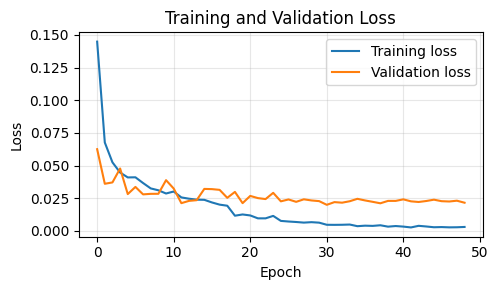

In [68]:
plt.figure(figsize=(5, 3))

plt.plot(epoch_loss_list, label='Training loss')
plt.plot(epoch_loss_list_val, label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/loss.png")

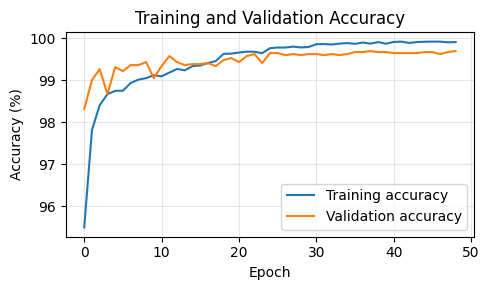

In [69]:
plt.figure(figsize=(5, 3))

plt.plot(epoch_acc_list, label='Training accuracy')
plt.plot(epoch_acc_list_val, label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/acc.png")

### 5.2 Loading the Best Model

Rather than evaluating the model using the weights from the final training epoch, the checkpoint with the highest validation accuracy is restored.

This ensures that subsequent evaluation uses the best-performing model observed during training.

The model is then switched to evaluation mode, disabling training-specific behavior such as dropout.

In [70]:
# load the best model checkpoint

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=True
)

Net.load_state_dict(checkpoint["model"])
Net.eval()

print(f"Best validation accuracy: {checkpoint['best_score']:.2f}%")
print(f"Best epoch: {checkpoint['epoch']}")

Best validation accuracy: 99.69%
Best epoch: 37


### 5.3 Overall Classification Performance

The restored model is evaluated on the validation set, which contains images excluded from gradient-based training.

Overall accuracy measures the proportion of correctly classified images:

$$\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}}$$

Although accuracy provides a useful summary, it does not show how performance differs between individual digit classes. Therefore, additional classification metrics and visualizations are used for a more detailed evaluation.

In [71]:
# collect validation predictions

all_predictions = []
all_labels = []
misclassified_images = []
misclassified_labels = []
misclassified_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = Net(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

        # find incorrectly classified images
        incorrect = predicted.cpu() != labels

        for i in torch.where(incorrect)[0]:

            if len(misclassified_images) < 20:

                misclassified_images.append(images[i].cpu())

                misclassified_labels.append(labels[i].item())

                misclassified_predictions.append(predicted[i].item())

### 5.4 Confusion Matrix

The confusion matrix provides a breakdown of correct and incorrect predictions for each digit class.

Rows represent the true labels, while columns represent the predicted labels.

- Values along the main diagonal represent correctly classified images.
- Values outside the diagonal represent misclassifications.

This visualization helps identify which digits the model tends to confuse with one another.

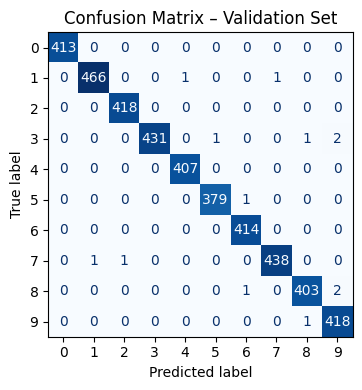

In [72]:
# generate confusion matrix

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(5, 4))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Confusion Matrix – Validation Set")
plt.tight_layout()
plt.savefig("/kaggle/working/cm.png")
plt.show()

### 5.5 Per-Class Classification Metrics

Precision, recall, and F1-score provide a more detailed view of classification performance.

- **Precision:** Of all images predicted as a particular digit, how many were classified correctly?
- **Recall:** Of all images belonging to a particular digit, how many were correctly identified?
- **F1-score:** The harmonic mean of precision and recall.

These metrics are calculated separately for each digit (0–9), making it possible to identify classes that are more difficult for the model to distinguish.

In [73]:
# generate classification report

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=np.arange(10),
        target_names=[str(i) for i in range(10)],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       413
           1     0.9979    0.9957    0.9968       468
           2     0.9976    1.0000    0.9988       418
           3     1.0000    0.9908    0.9954       435
           4     0.9975    1.0000    0.9988       407
           5     0.9974    0.9974    0.9974       380
           6     0.9952    1.0000    0.9976       414
           7     0.9977    0.9955    0.9966       440
           8     0.9951    0.9926    0.9938       406
           9     0.9905    0.9976    0.9941       419

    accuracy                         0.9969      4200
   macro avg     0.9969    0.9970    0.9969      4200
weighted avg     0.9969    0.9969    0.9969      4200



### 5.6 Error Analysis

Examining individual misclassified images provides insight into the limitations of the model.

Some handwritten digits have similar visual characteristics, while others may contain unusual shapes, ambiguous strokes, or inconsistent writing styles.

By inspecting incorrectly classified samples alongside their true and predicted labels, we can better understand the types of errors made by the network.

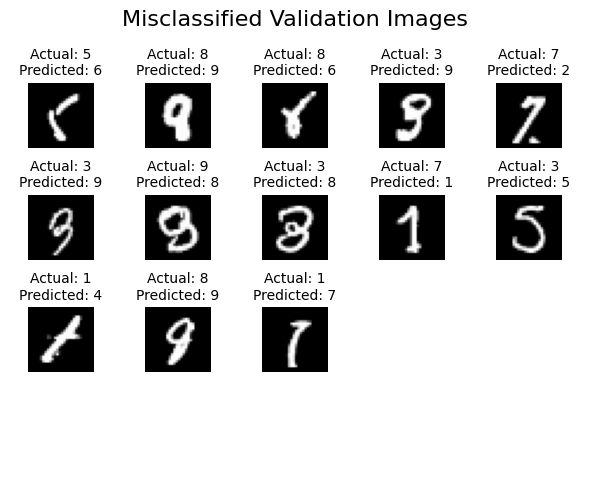

In [74]:
# visualize misclassified images

fig, axes = plt.subplots(4, 5, figsize=(6, 5))

for i, ax in enumerate(axes.flat):

    if i < len(misclassified_images):

        img = misclassified_images[i].squeeze().numpy()

        # if the image has multiple channels, use the first.
        if img.ndim == 3:
            img = img[0]

        # reverse normalization
        img = img * 0.5 + 0.5

        ax.imshow(img, cmap="gray", vmin=0, vmax=1)

        ax.set_title(
            f"Actual: {misclassified_labels[i]}\n"
            f"Predicted: {misclassified_predictions[i]}",
            fontsize=10
        )

    ax.axis("off")

plt.suptitle("Misclassified Validation Images", fontsize=16)
plt.tight_layout()
plt.savefig("/kaggle/working/misclassified.png")
plt.show()

In [76]:
# calculate and verify validation accuracy

accuracy = (np.array(all_predictions) == np.array(all_labels)).mean() * 100

print(f"Validation accuracy: {accuracy:.4f}%")
print(f"Correct predictions: {sum(np.array(all_predictions) == np.array(all_labels))}")
print(f"Incorrect predictions: {sum(np.array(all_predictions) != np.array(all_labels))}")

Validation accuracy: 99.6905%
Correct predictions: 4187
Incorrect predictions: 13


## 6. Test Predictions and Kaggle Submission

After evaluating the model on the validation set, the selected checkpoint is used to generate predictions for the unlabeled Kaggle test dataset.

The test images undergo the same preprocessing used for validation images, without data augmentation.

The predicted digit classes are then combined with their corresponding image identifiers to create a submission file in the format required by the Kaggle competition.

### 6.1 Generating Test Predictions

The model generates predictions for each image in the test dataset.

Since the test dataset does not contain ground-truth labels, these predictions cannot be evaluated locally using classification metrics.

The model is kept in evaluation mode, and gradient computation is disabled during inference.

In [75]:
# do the predictions on the test set

pred_list = []

print(df_test.shape)

im_id_list = np.arange(1, df_test.shape[0] + 1)

with torch.no_grad():

    for i, data in enumerate(test_loader, 0):

        images, _ = data
        images = images.to(device)

        outputs = Net(images)

        _, predicted = torch.max(outputs, 1)

        pred_list.extend(predicted.tolist())

(28000, 784)


### 6.2 Creating the Submission File

The predicted labels are combined with sequential image identifiers to construct the submission DataFrame.

The resulting CSV file contains two columns:

- `ImageId`: Identifier of the test image, starting from 1.
- `Label`: Predicted digit class (0–9).

The file is saved as `submission.csv` and can be uploaded to the Kaggle Digit Recognizer competition.

In [77]:
submission = pd.DataFrame({"ImageId": im_id_list, "Label" : pred_list})

In [78]:
submission.to_csv("submission.csv", index=False)

## 7. Results and Discussion

This section compares the results of different training configurations and discusses the impact of augmentation, model choices, and potential dataset labeling issues on classification performance.

### 7.1 Experimental Setup

The results presented below were obtained from separate training runs, each using a different configuration. The notebook contains the implementation of the augmentation methods, but not every method is active in the current training pipeline.

For the current run, **only random affine transformations are enabled**. Random erasing and morphological transformations (dilation and erosion) are implemented but commented out in the training transform definition. To evaluate their individual and combined effects, the corresponding configurations were enabled and trained separately.

The results of these additional runs are summarized in the table below. Their individual training procedures and outputs are not reproduced in this notebook.

In addition to data augmentation, several other choices can influence model performance, including:

**Model architecture**: number of convolutional layers, number of filters, kernel sizes, pooling strategy, and fully connected layer dimensions.

**Optimization settings**: optimizer, learning rate, and weight decay.

**Training configuration**: batch size, maximum number of epochs, learning rate scheduling, and early stopping.

**Data augmentation**: type, parameters, and probability of applying each transformation.

The reported results therefore reflect the complete configuration used in each experiment, rather than the effect of augmentation alone.

### 7.2 Comparison of Data Augmentation Strategies

| Augmentation configuration | Validation accuracy | Incorrect predictions |
| --- | --- | --- |
| No augmentation | 99.43% | 24 |
| Affine | 99.74% | 11 |
| Random erasing | 99.38% | 26 |
| Dilation | 99.50% | 21 |
| Affine + dilation | 99.64% | 15 |
| All three | 99.60% | 17 |

Note: Each configuration was trained separately. The table records the results of those runs; the corresponding experiment code and training outputs are not all included in this notebook.

### 7.3 Observations

Affine transformations achieved the highest validation accuracy among the tested configurations. Small rotations, translations, and scaling appear to improve the model's ability to generalize to variations in handwriting.

Dilation produced a small improvement over training without augmentation, while random erasing alone performed slightly worse.

Combining multiple transformations did not outperform affine augmentation alone. This suggests that applying more augmentation does not necessarily lead to better results; the type and intensity of transformations matter.

The results also depend on model architecture and training hyperparameters, so the differences should not be attributed exclusively to augmentation.

**Potentially incorrect labels:** Inspecting the misclassified images also reveals examples where the assigned labels appear to be incorrect or inconsistent with the digit shown. These cases may contribute to the validation error, since a prediction that matches the visually correct digit is still counted as incorrect if it differs from the dataset label. This highlights a limitation of evaluating model performance solely against the provided labels.

Although only validation examples were inspected, it is reasonable to assume that the training set may also contain mislabeled images. Unlike validation label errors, which affect only the evaluation, mislabeled training examples can directly affect the learning process by providing incorrect supervision. The model may therefore learn misleading patterns or associations, potentially affecting its ability to generalize to unseen data.

### 7.4 Limitations and Further Experiments

Each configuration was evaluated using a single training run. Since model initialization, data-loader shuffling, and stochastic augmentation introduce randomness, repeated runs with different random seeds would provide a more reliable comparison.

Furthermore, the validation set was used both for model selection and performance evaluation. An independent test set or repeated validation experiments would provide a stronger estimate of generalization.

Further experiments could investigate different model architectures, batch sizes, learning rates, regularization settings, and augmentation parameters to determine how these choices interact.